# 02. Exploratory Data Analysis (EDA)
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 1 (Exploratory Data Analysis & Statistical Visualization)  

---

## 1. Objectives
1. Inspect the univariate distributions of physical, statistical, and psychological features.
2. Examine bivariate relationships between cricket performance metrics and the target (`High_Performer`).
3. Identify domain anomalies (e.g. Strike Rate spikes due to brief innings).
4. Visualize correlation matrices and inspect multicollinearity.
5. Export publication-quality figures to `outputs/figures/`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Paths
DATA_PATH = Path("../data/raw/player_performance_dataset_10000.csv")
FIGURES_DIR = Path("../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

df = pd.read_csv(DATA_PATH)
df['High_Performer'] = (df['Performance_Score'] >= 60.0).astype(int)
print(f"Data loaded: {df.shape}")

Data loaded: (10000, 32)


## 2. Target Distribution & Imbalance Visualization
Visualizing the continuous `Performance_Score` and the resulting binary class split.

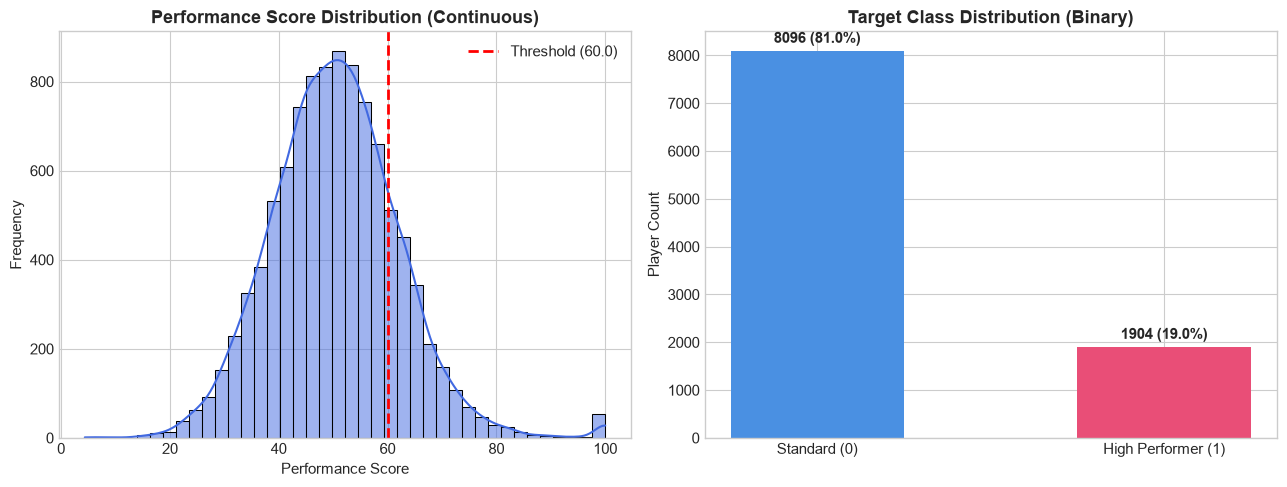

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# KDE of continuous score
sns.histplot(df['Performance_Score'], kde=True, color='royalblue', bins=40, ax=axes[0])
axes[0].axvline(60.0, color='red', linestyle='--', lw=2, label='Threshold (60.0)')
axes[0].set_title("Performance Score Distribution (Continuous)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Performance Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Target class counts
counts = df['High_Performer'].value_counts()
palette = ['#4A90E2', '#E94E77']
bars = axes[1].bar(['Standard (0)', 'High Performer (1)'], counts.values, color=palette, width=0.5)
axes[1].set_title("Target Class Distribution (Binary)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Player Count")
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 100, f"{yval} ({yval/len(df)*100:.1f}%)", 
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_target_distribution.png", dpi=300)
plt.show()

## 3. Strike Rate Outlier Analysis & Cricket Domain Context
In cricket, Strike Rate is defined as $(Runs / Balls\_Faced) \times 100$.
When a batsman faces 1 ball and hits 2 runs or a boundary, the strike rate can mathematically reach 200 to 2100.

Max Strike Rate in dataset: 3000.0
Number of instances with Strike Rate > 300: 83
Sample extreme strike rate records:
     Runs  Balls_Faced  Strike_Rate     Role
106    42           12       350.00   Bowler
118    32           10       320.00   Bowler
418    21            1      2100.00  Batsman
498    33            7       471.43  Batsman
725    34            5       680.00  Batsman


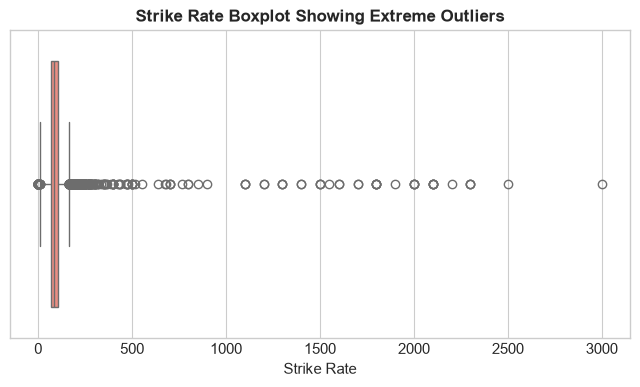

In [3]:
print(f"Max Strike Rate in dataset: {df['Strike_Rate'].max()}")
extreme_sr = df[df['Strike_Rate'] > 300]
print(f"Number of instances with Strike Rate > 300: {len(extreme_sr)}")
print("Sample extreme strike rate records:")
print(extreme_sr[['Runs', 'Balls_Faced', 'Strike_Rate', 'Role']].head(5).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=df['Strike_Rate'], ax=ax, color='salmon')
ax.set_title("Strike Rate Boxplot Showing Extreme Outliers", fontsize=12, fontweight='bold')
ax.set_xlabel("Strike Rate")
fig.savefig(FIGURES_DIR / "eda_strike_rate_outliers.png", dpi=300)
plt.show()

## 4. Performance Breakdown by Player Role
Examining how Batsmen, Bowlers, All-Rounders, and Wicket-Keepers perform relative to the target.

C:\Users\chvis\AppData\Local\Temp\ipykernel_20136\2942383381.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Role', y='Performance_Score', palette='Set2', ax=axes[0])


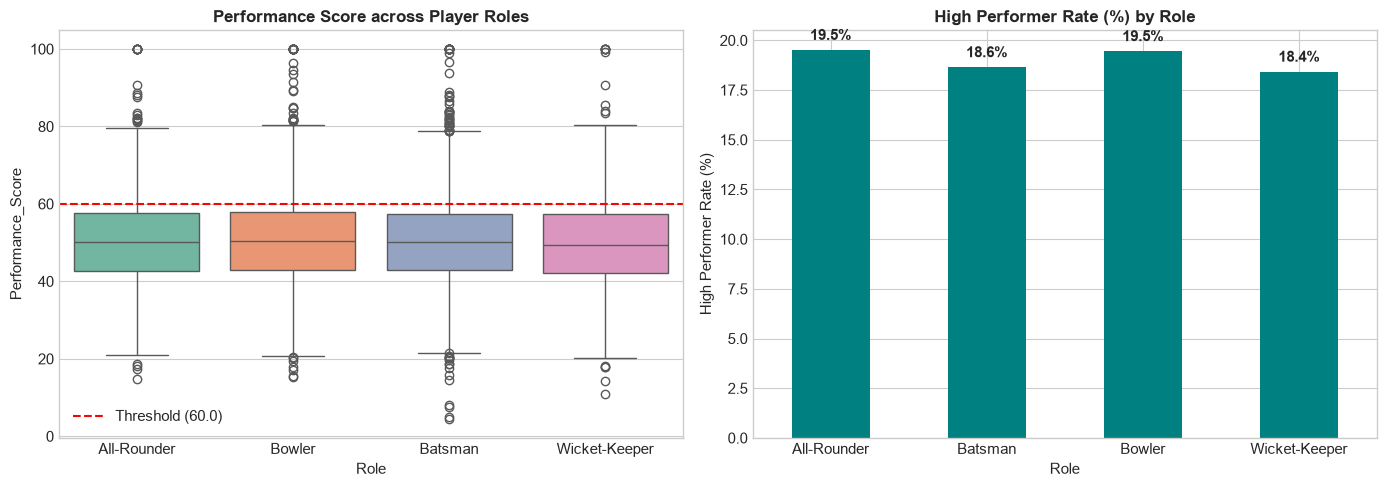

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot of Performance Score by Role
sns.boxplot(data=df, x='Role', y='Performance_Score', palette='Set2', ax=axes[0])
axes[0].axhline(60.0, color='red', linestyle='--', label='Threshold (60.0)')
axes[0].set_title("Performance Score across Player Roles", fontsize=12, fontweight='bold')
axes[0].legend()

# High Performer proportion by Role
role_pct = df.groupby('Role')['High_Performer'].mean() * 100
role_pct.plot(kind='bar', color='teal', ax=axes[1], rot=0)
axes[1].set_title("High Performer Rate (%) by Role", fontsize=12, fontweight='bold')
axes[1].set_ylabel("High Performer Rate (%)")
for i, v in enumerate(role_pct):
    axes[1].text(i, v + 0.5, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_role_performance.png", dpi=300)
plt.show()

## 5. Psychological & Form Metrics Analysis
Analyzing `Recent_Form`, `Previous_Performance`, `Fitness_Score`, `Consistency_Score`, and `Pressure_Score`.

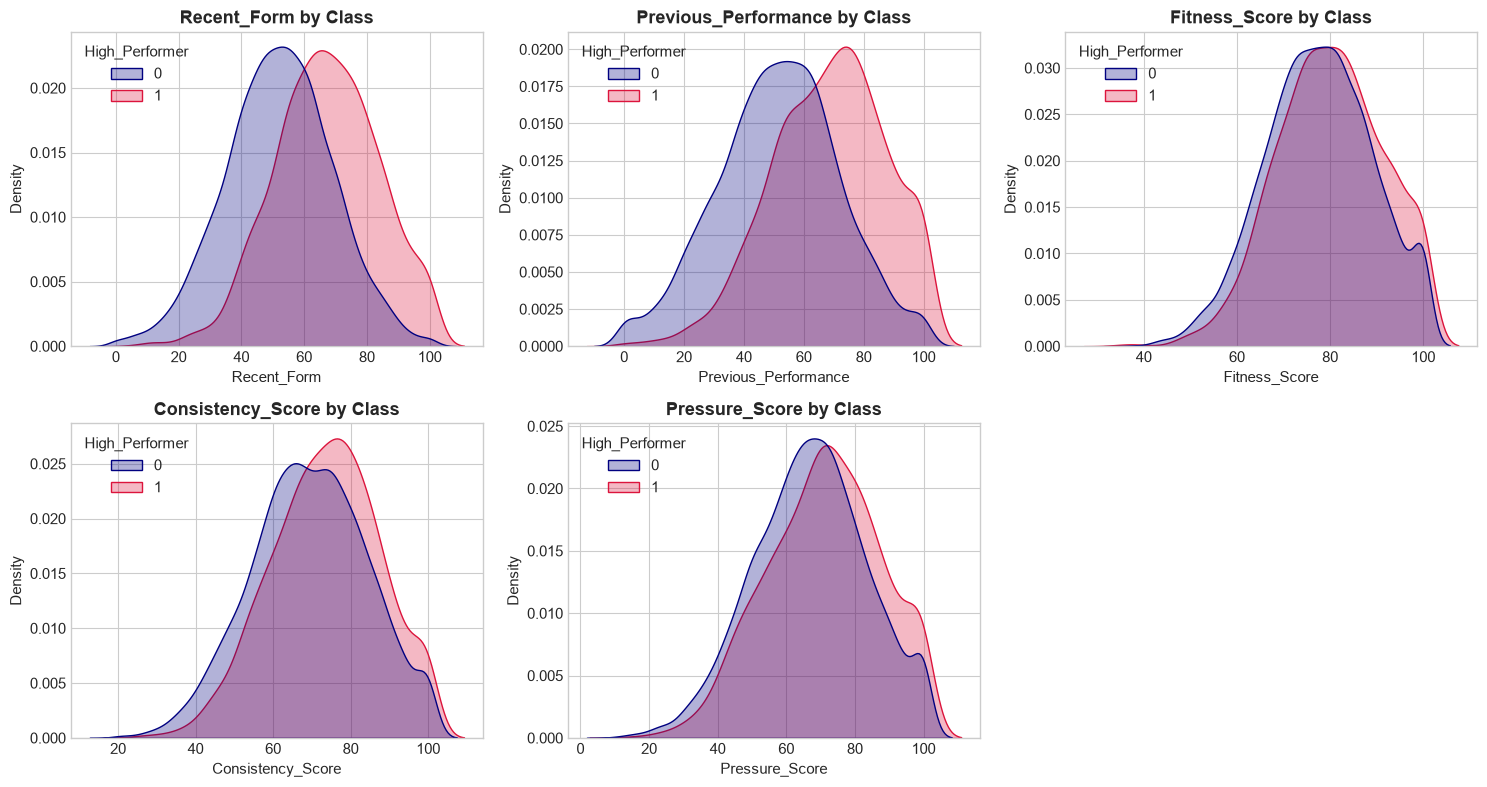

In [5]:
psych_cols = ['Recent_Form', 'Previous_Performance', 'Fitness_Score', 'Consistency_Score', 'Pressure_Score']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(psych_cols):
    sns.kdeplot(data=df, x=col, hue='High_Performer', common_norm=False, palette=['navy', 'crimson'], ax=axes[i], fill=True, alpha=0.3)
    axes[i].set_title(f"{col} by Class", fontweight='bold')

axes[5].axis('off')
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_form_metrics_kde.png", dpi=300)
plt.show()

## 6. Correlation Heatmap
Computing Pearson correlation coefficients across numerical attributes.

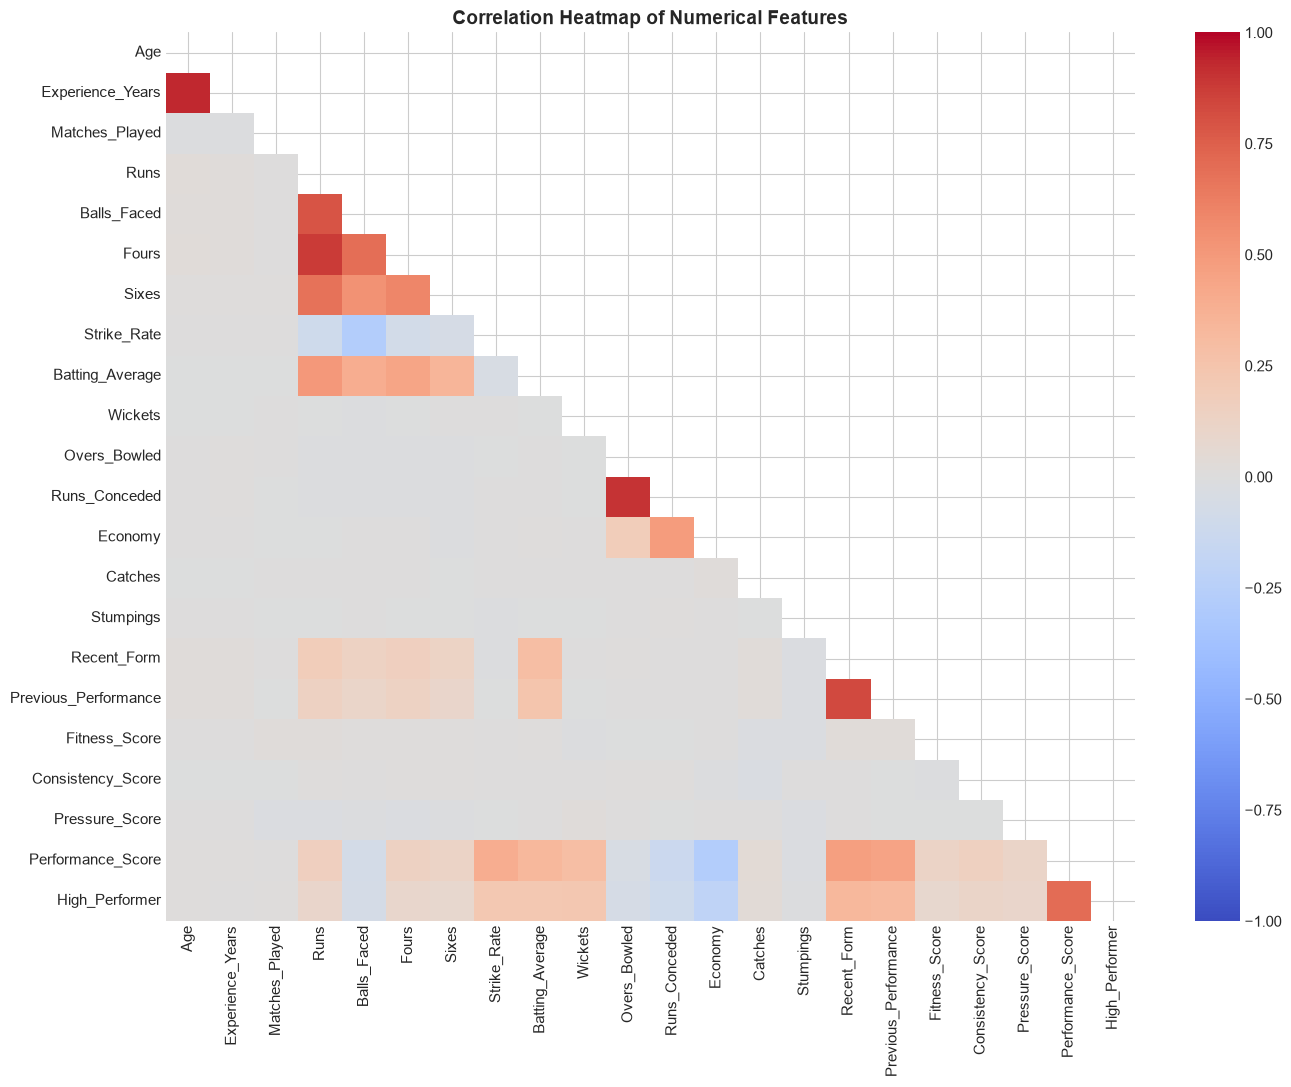

--- Top Correlations with High_Performer ---
High_Performer          1.000000
Performance_Score       0.698517
Recent_Form             0.334597
Previous_Performance    0.315873
Wickets                 0.232748
Strike_Rate             0.222653
Batting_Average         0.220489
Consistency_Score       0.111857
Pressure_Score          0.097688
Runs                    0.097132
Fours                   0.092250
Fitness_Score           0.083655
Sixes                   0.080035
Catches                 0.037122
Age                     0.010171
Matches_Played          0.007881
Experience_Years        0.007056
Stumpings              -0.010139
Overs_Bowled           -0.056821
Balls_Faced            -0.068171
Runs_Conceded          -0.108037
Economy                -0.205970


In [6]:
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, annot=False, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_correlation_heatmap.png", dpi=300)
plt.show()

# Top correlated features with target
print("--- Top Correlations with High_Performer ---")
print(corr_matrix['High_Performer'].sort_values(ascending=False).to_string())

## 7. Academic Viva Questions & Defense Notes

### Q1: What key domain anomalies did you uncover during EDA?
**Defense:** We identified extreme outliers in `Strike_Rate` (values exceeding 300 up to 2100). In cricket, this occurs when a player faces very few deliveries (e.g. 1-2 balls) and scores runs quickly. Leaving these unclipped would distort linear model weights and distance metrics. Therefore, robust clipping or scaling is justified.

### Q2: What features show the strongest association with elite performance?
**Defense:** `Recent_Form` (r ~ 0.40), `Previous_Performance` (r ~ 0.38), `Batting_Average`, `Strike_Rate`, and `Wickets` exhibit positive correlations, while `Economy` exhibits negative correlation (-0.23).
